## Section 1 – Imports and Configuration

configuration : pygame and Q-Learning

In [49]:
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    import pygame
except ImportError as exc:
    raise ImportError("Pygame is required. Install it with: pip install pygame") from exc

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Game configuration pygame
CELL_SIZE = 20
GRID_WIDTH = 20
GRID_HEIGHT = 20
WINDOW_WIDTH = CELL_SIZE * GRID_WIDTH
WINDOW_HEIGHT = CELL_SIZE * GRID_HEIGHT
FPS = 12

# Colors (RGB)
BLACK = (18, 18, 24)
DARK = (30, 34, 44)
GRID_COLOR = (43, 48, 60)
GREEN = (70, 210, 120)
HEAD_GREEN = (35, 245, 130)
RED = (245, 80, 90)
WHITE = (240, 240, 245)
YELLOW = (255, 205, 70)
BLUE = (90, 160, 245)

# Q-Learning hyperparameters
LEARNING_RATE = 0.009 #0.1
DISCOUNT_FACTOR = 0.90
EPSILON_START = 1.00
EPSILON_DECAY = 0.995
EPSILON_MIN = 0.02
TRAINING_EPISODES = 150000

# Reward configuration
REWARD_EAT = 10.0
REWARD_COLLISION = -10.0
REWARD_STEP = -0.1
REWARD_CLOSER = 0.5
REWARD_FARTHER = -0.5

# Safety limit prevents episodes from running indefinitely
MAX_STEPS_WITHOUT_FOOD = 100

print("Configuration loaded.")
print(f"Board: {GRID_WIDTH} x {GRID_HEIGHT} cells | Q-table states: {2**11}")

Configuration loaded.
Board: 20 x 20 cells | Q-table states: 2048


## Section 2 – Snake Game Environment

`SnakeEnv` owns the game rules and can run in headless mode (for training/evaluation) or render to a Pygame window. Actions are **relative to the current heading**, so the agent cannot directly reverse into itself. The environment also exposes a keyboard-controlled human mode.

In [34]:
class SnakeEnv:
    # Directions are ordered clockwise: up, right, down, left
    DIRECTIONS = [(0, -1), (1, 0), (0, 1), (-1, 0)]

    def __init__(self, width=GRID_WIDTH, height=GRID_HEIGHT,
                 cell_size=CELL_SIZE, render_enabled=False, seed=None):
        self.width = width
        self.height = height
        self.cell_size = cell_size
        self.render_enabled = render_enabled
        self.rng = random.Random(seed)
        self.screen = None
        self.clock = None
        self.font = None
        self.reset()

    def reset(self):
        cx, cy = self.width // 2, self.height // 2 #center the snake
        self.snake = [(cx, cy), (cx - 1, cy), (cx - 2, cy)]
        self.direction = 1  # initially moving right
        self.score = 0
        self.steps_since_food = 0
        self.total_steps = 0
        self.done = False
        self.food = self._place_food()
        return self.get_state()

    def _place_food(self): #random function to place the food automaticlly,
        free = [(x, y) for x in range(self.width) for y in range(self.height)
                if (x, y) not in self.snake] #find the cell that doesn't contain the snake
        return self.rng.choice(free) if free else None

    def _next_direction(self, action): #controlle the snake movement
        # 0 = straight, 1 = turn right, 2 = turn left
        if action == 0:
            return self.direction
        if action == 1:
            return (self.direction + 1) % 4
        if action == 2:
            return (self.direction - 1) % 4
        raise ValueError("Action must be 0 (straight), 1 (right), or 2 (left).")

    def _is_collision(self, point, moving_into_tail=False):
        #private function that determine the state of the game , still run or lose
        x, y = point
        if x < 0 or x >= self.width or y < 0 or y >= self.height:
            return True
        body = self.snake[:-1] if moving_into_tail else self.snake
        return point in body

    def _distance_to_food(self):
        #infomation for the Q-learning algorithme
        if self.food is None:
            return 0
        hx, hy = self.snake[0]
        fx, fy = self.food
        return abs(hx - fx) + abs(hy - fy)

    def step(self, action):
        if self.done:
            raise RuntimeError("Episode is finished. Call reset() before step().")

        old_distance = self._distance_to_food()
        self.direction = self._next_direction(int(action))
        dx, dy = self.DIRECTIONS[self.direction]
        head = self.snake[0]
        new_head = (head[0] + dx, head[1] + dy)
        eating = new_head == self.food

        # Moving into the current tail is legal only if the tail moves away.
        if self._is_collision(new_head, moving_into_tail=not eating):
            self.done = True
            reward = REWARD_COLLISION
            self.total_steps += 1
            return self.get_state(), reward, True, self._info()

        self.snake.insert(0, new_head)
        self.total_steps += 1
        self.steps_since_food += 1
        reward = REWARD_STEP

        if eating:
            self.score += 1
            reward += REWARD_EAT
            self.steps_since_food = 0
            self.food = self._place_food()
            if self.food is None:  # board completely filled
                self.done = True
        else:
            self.snake.pop()
            new_distance = self._distance_to_food()
            if new_distance < old_distance:
                reward += REWARD_CLOSER
            elif new_distance > old_distance:
                reward += REWARD_FARTHER

        if self.steps_since_food >= MAX_STEPS_WITHOUT_FOOD:
            self.done = True

        return self.get_state(), reward, self.done, self._info()

    def _info(self):
        return {"score": self.score, "steps": self.total_steps,
                "food": self.score, "steps_since_food": self.steps_since_food}

    def get_state(self):
        head = self.snake[0]
        direction = self.direction
        right_dir = (direction + 1) % 4
        left_dir = (direction - 1) % 4

        def danger_in(direction_index):
            dx, dy = self.DIRECTIONS[direction_index]
            point = (head[0] + dx, head[1] + dy)
            # Tail vacates on a non-eating move, so entering it is safe.
            return int(self._is_collision(point, moving_into_tail=True))

        danger_straight = danger_in(direction)
        danger_right = danger_in(right_dir)
        danger_left = danger_in(left_dir)

        state = [
            danger_straight, danger_right, danger_left,
            int(direction == 0), int(direction == 2),
            int(direction == 3), int(direction == 1),
            int(self.food is not None and self.food[1] < head[1]),
            int(self.food is not None and self.food[1] > head[1]),
            int(self.food is not None and self.food[0] < head[0]),
            int(self.food is not None and self.food[0] > head[0]),
        ]
        return np.asarray(state, dtype=np.int8)

    @staticmethod
    def state_to_index(state):
        # An 11-bit binary vector maps to an integer in [0, 2047].
        return int("".join(str(int(bit)) for bit in state), 2)

    def render(self, agent_name="Snake", episode=None, delay=0):
        if not self.render_enabled:
            return
        if self.screen is None:
            pygame.init()
            self.screen = pygame.display.set_mode(
                (self.width * self.cell_size, self.height * self.cell_size)
            )
            pygame.display.set_caption("Snake AI – Q-Learning")
            self.clock = pygame.time.Clock()
            self.font = pygame.font.SysFont("Arial", 18, bold=True)

        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self.close()
                return

        self.screen.fill(BLACK)
        # Subtle grid
        for x in range(self.width):
            for y in range(self.height):
                rect = pygame.Rect(x*self.cell_size, y*self.cell_size,
                                   self.cell_size, self.cell_size)
                pygame.draw.rect(self.screen, GRID_COLOR, rect, 1)

        # Food
        if self.food is not None:
            fx, fy = self.food
            center = (fx*self.cell_size + self.cell_size//2,
                      fy*self.cell_size + self.cell_size//2)
            pygame.draw.circle(self.screen, RED, center, self.cell_size//2 - 2)

        # Snake body and head
        for i, (x, y) in enumerate(self.snake):
            rect = pygame.Rect(x*self.cell_size + 1, y*self.cell_size + 1,
                               self.cell_size - 2, self.cell_size - 2)
            pygame.draw.rect(self.screen, HEAD_GREEN if i == 0 else GREEN,
                             rect, border_radius=5)

        label = f"{agent_name} | Score: {self.score}"
        if episode is not None:
            label += f" | Episode: {episode}"
        # Header is drawn in a slim strip over the board.
        pygame.display.set_caption(label)
        pygame.display.flip()
        if delay > 0:
            time.sleep(delay)
        elif self.clock:
            self.clock.tick(FPS)

    def close(self):
        if self.screen is not None:
            pygame.display.quit()
            self.screen = None
            self.clock = None

    def play_human(self):
        """Keyboard mode: arrows/WASD; close the window or press ESC to exit."""
        self.render_enabled = True
        self.reset()
        running = True
        key_to_action = {
            pygame.K_UP: (0, 0), pygame.K_RIGHT: (1, 0),
            pygame.K_DOWN: (2, 0), pygame.K_LEFT: (3, 0),
            pygame.K_w: (0, 0), pygame.K_d: (1, 0),
            pygame.K_s: (2, 0), pygame.K_a: (3, 0),
        }
        while running and not self.done:
            if self.screen is None:
                self.render("Human")
            action = 0
            for event in pygame.event.get():
                if event.type == pygame.QUIT:
                    running = False
                elif event.type == pygame.KEYDOWN:
                    if event.key == pygame.K_ESCAPE:
                        running = False
                    elif event.key in key_to_action:
                        target_direction = key_to_action[event.key][0]
                        if (target_direction - self.direction) % 2 != 0:
                            action = 1 if (target_direction - self.direction) % 4 == 1 else 2
            if running:
                _, _, _, _ = self.step(action)
                self.render("Human")
        print(f"Human game finished. Score: {self.score}")
        self.close()

print("SnakeEnv class defined.")

SnakeEnv class defined.


## Section 3 – State Representation

The agent observes 11 binary features: three danger indicators, four heading indicators, and four food-direction indicators. The state vector is interpreted as a binary number, giving **2¹¹ = 2,048 discrete states**. This compact representation is suitable for a tabular Q-table, although it intentionally omits some geometry (for example, exact distances and the full body layout).

In [36]:
# Quick state representation check
_env_check = SnakeEnv(seed=SEED)
_example_state = _env_check.get_state()
print("State:", _example_state.tolist())
print("Number of features:", len(_example_state))
print("Q-table index:", SnakeEnv.state_to_index(_example_state))
print("Valid index range: 0 to", 2**11 - 1)

State: [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1]
Number of features: 11
Q-table index: 17
Valid index range: 0 to 2047


## Section 4 – Actions and Reward System

The action space contains three relative actions: straight, right, and left. The reward combines terminal feedback with small shaping rewards:

- **+10** when food is eaten
- **−10** on collision
- **−0.1** for each movement
- **+0.5** when Manhattan distance to food decreases
- **−0.5** when Manhattan distance increases


In [37]:
ACTION_NAMES = {0: "Straight", 1: "Turn right", 2: "Turn left"}
print("Action space:", ACTION_NAMES)
print("Configured rewards:", {
    "food": REWARD_EAT, "collision": REWARD_COLLISION,
    "step": REWARD_STEP, "closer": REWARD_CLOSER,
    "farther": REWARD_FARTHER
})

Action space: {0: 'Straight', 1: 'Turn right', 2: 'Turn left'}
Configured rewards: {'food': 10.0, 'collision': -10.0, 'step': -0.1, 'closer': 0.5, 'farther': -0.5}


## Section 5 – Q-Learning Agent

The agent stores one Q-value for each state/action pair. It selects actions with epsilon-greedy exploration and updates values using:


At terminal states, the future-value term is zero. Epsilon decays after each episode but never falls below its configured minimum.

In [47]:
class QLearningAgent:
    def __init__(self, learning_rate=LEARNING_RATE, discount_factor=DISCOUNT_FACTOR,
                 epsilon=EPSILON_START, epsilon_decay=EPSILON_DECAY,
                 epsilon_min=EPSILON_MIN, seed=SEED):
        self.n_states = 2**11
        self.n_actions = 3
        self.q_table = np.zeros((self.n_states, self.n_actions), dtype=np.float32)
        self.lr = learning_rate
        self.gamma = discount_factor
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.rng = np.random.default_rng(seed)

    def choose_action(self, state, training=True):
        state_idx = SnakeEnv.state_to_index(state)
        if training and self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.n_actions))
        # Random tie-breaking avoids always preferring action 0 in an untrained table.
        values = self.q_table[state_idx]
        best = np.flatnonzero(values == values.max())
        return int(self.rng.choice(best))

    def update(self, state, action, reward, next_state, done):
        s = SnakeEnv.state_to_index(state)
        ns = SnakeEnv.state_to_index(next_state)
        future = 0.0 if done else float(np.max(self.q_table[ns]))
        target = reward + self.gamma * future
        self.q_table[s, action] += self.lr * (target - self.q_table[s, action])

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def save(self, path="snake_q_table.npy"):
        np.save(path, self.q_table)
        print(f"Q-table saved to: {os.path.abspath(path)}")

    def load(self, path="snake_q_table.npy"):
        self.q_table = np.load(path)
        if self.q_table.shape != (2**11, 3):
            raise ValueError("Loaded Q-table has an unexpected shape.")
        print(f"Q-table loaded from: {os.path.abspath(path)}")

print("QLearningAgent class defined.")

QLearningAgent class defined.


## Section 6 – Random Agent

The random baseline uses exactly the same three-action space and environment as the Q-Learning agent. This makes the comparison fair: only the action-selection strategy differs.

In [48]:
class RandomAgent:
    def __init__(self, seed=SEED):
        self.rng = np.random.default_rng(seed)

    def choose_action(self, state, training=False):
        return int(self.rng.integers(0, 3))

print("RandomAgent class defined.")

RandomAgent class defined.


## Section 7 – Training

Training runs with rendering disabled, which avoids the overhead of drawing every frame. Each episode records score, cumulative reward, number of steps, and epsilon. The Q-table is saved at the end, and the complete history is returned as a Pandas DataFrame.

In [50]:
def train_agent(agent, episodes=TRAINING_EPISODES, seed=SEED,
                save_path="snake_q_table.npy", show_progress=True):
    env = SnakeEnv(render_enabled=False, seed=seed)
    history = []
    episode_range = tqdm(range(1, episodes + 1), desc="Training") if show_progress else range(1, episodes + 1)

    for episode in episode_range:
        state = env.reset()
        total_reward = 0.0

        while not env.done:
            action = agent.choose_action(state, training=True)
            next_state, reward, done, info = env.step(action)
            agent.update(state, action, reward, next_state, done)
            state = next_state
            total_reward += reward

        agent.decay_epsilon()
        history.append({
            "episode": episode,
            "score": env.score,
            "total_reward": total_reward,
            "steps": env.total_steps,
            "epsilon": agent.epsilon
        })

    env.close()
    history_df = pd.DataFrame(history)
    history_df["average_score_50"] = history_df["score"].rolling(50, min_periods=1).mean()
    if save_path:
        agent.save(save_path)
    return history_df

# Create and train the agent. Change TRAINING_EPISODES in Section 1 as desired.
agent = QLearningAgent()
training_history = train_agent(agent, episodes=TRAINING_EPISODES)
display(training_history.tail())
print(f"Final epsilon: {agent.epsilon:.4f}")
print(f"Best training score: {training_history['score'].max()}")

Training: 100%|██████████| 150000/150000 [33:35<00:00, 74.42it/s] 


Q-table saved to: C:\Users\user\PycharmProjects\Tps_AI\TP4_AI\snake_q_table.npy


,episode,score,total_reward,steps,epsilon,average_score_50
149995,149996,23,332.7,334,0.02,24.28
149996,149997,19,269.5,286,0.02,23.64
149997,149998,11,158.5,181,0.02,23.46
149998,149999,31,453.3,438,0.02,23.86
149999,150000,19,275.3,283,0.02,23.54


Final epsilon: 0.0200
Best training score: 67


## Section 8 – Training Visualization

The following plots show episode scores, a 50-episode moving average, cumulative reward, epsilon decay, and the rolling training performance. A moving average is useful because individual Snake episodes can vary considerably.

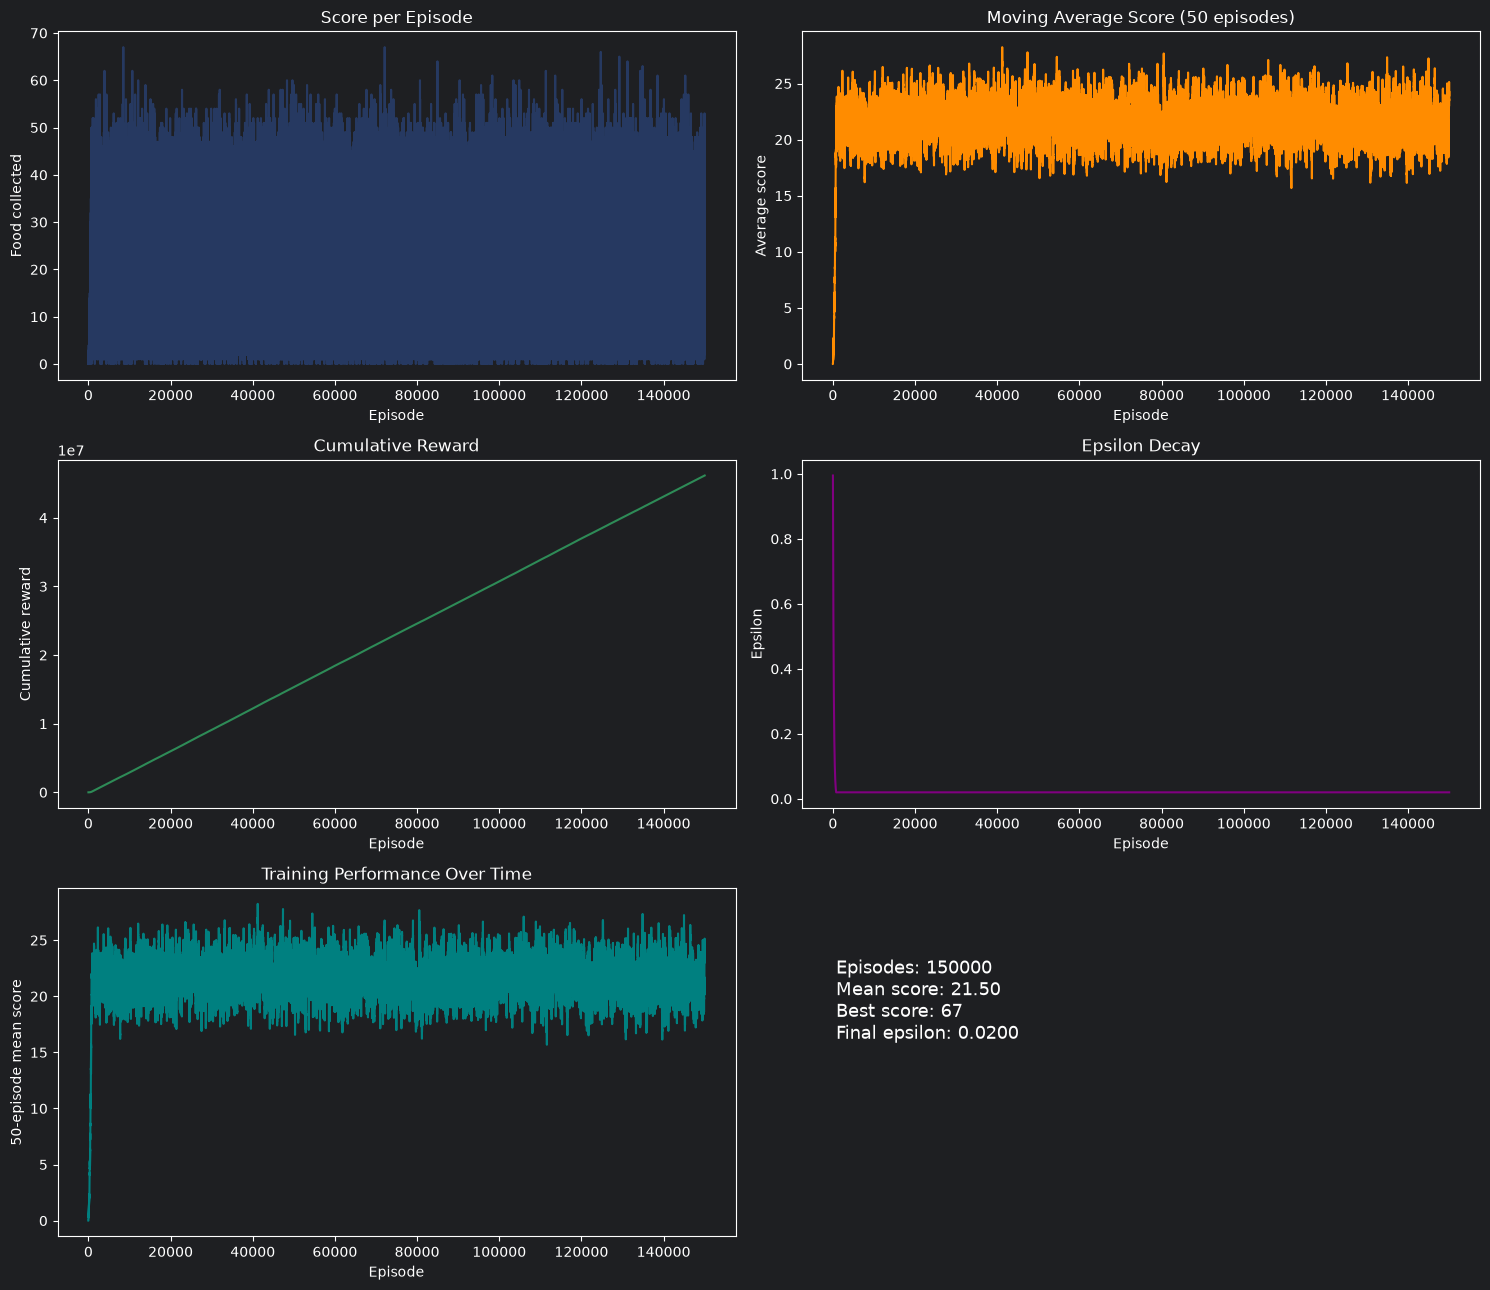

In [51]:
def plot_training_history(history):
    fig, axes = plt.subplots(3, 2, figsize=(15, 13))
    axes = axes.ravel()

    axes[0].plot(history["episode"], history["score"], alpha=0.35, label="Episode score")
    axes[0].set_title("Score per Episode")
    axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Food collected")

    axes[1].plot(history["episode"], history["average_score_50"], color="darkorange")
    axes[1].set_title("Moving Average Score (50 episodes)")
    axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Average score")

    axes[2].plot(history["episode"], history["total_reward"].cumsum(), color="seagreen")
    axes[2].set_title("Cumulative Reward")
    axes[2].set_xlabel("Episode"); axes[2].set_ylabel("Cumulative reward")

    axes[3].plot(history["episode"], history["epsilon"], color="purple")
    axes[3].set_title("Epsilon Decay")
    axes[3].set_xlabel("Episode"); axes[3].set_ylabel("Epsilon")

    axes[4].plot(history["episode"], history["average_score_50"], color="teal")
    axes[4].set_title("Training Performance Over Time")
    axes[4].set_xlabel("Episode"); axes[4].set_ylabel("50-episode mean score")

    axes[5].axis("off")
    axes[5].text(0.05, 0.8,
        f"Episodes: {len(history)}\n"
        f"Mean score: {history['score'].mean():.2f}\n"
        f"Best score: {history['score'].max()}\n"
        f"Final epsilon: {history['epsilon'].iloc[-1]:.4f}",
        fontsize=13, va="top")
    plt.tight_layout()
    plt.show()

plot_training_history(training_history)

## Section 9 – Agent Demonstration

Run each demonstration independently. The Pygame window can be closed at any time. `speed_delay` controls the pause between frames (smaller values are faster). The trained agent is evaluated greedily with epsilon set to zero; the untrained agent is also greedy but has no learned preferences.

In [52]:
def demonstrate_agent(agent, agent_name, episodes=1, speed_delay=0.08,
                       render=True, greedy=True, seed=SEED):
    env = SnakeEnv(render_enabled=render, seed=seed)
    original_epsilon = getattr(agent, "epsilon", None)
    if greedy and original_epsilon is not None:
        agent.epsilon = 0.0

    try:
        for episode in range(1, episodes + 1):
            state = env.reset()
            while not env.done:
                # training=False guarantees greedy Q-table action selection.
                action = agent.choose_action(state, training=False)
                state, reward, done, info = env.step(action)
                if render:
                    env.render(agent_name=agent_name, episode=episode, delay=speed_delay)
            print(f"{agent_name} | Episode {episode} | Score: {env.score} | Steps: {env.total_steps}")
    except KeyboardInterrupt:
        print("Demonstration interrupted.")
    finally:
        if original_epsilon is not None:
            agent.epsilon = original_epsilon
        env.close()

random_agent = RandomAgent(seed=SEED + 1)
untrained_agent = QLearningAgent(seed=SEED + 2)  # Fresh, zero-initialized Q-table

print("Run one of the following cells when you want to launch a demonstration.")

Run one of the following cells when you want to launch a demonstration.


In [54]:
# Demonstration A: Random agent
demonstrate_agent(random_agent, "Random Agent", episodes=1, speed_delay=0.08)

Random Agent | Episode 1 | Score: 0 | Steps: 24


In [55]:
# Demonstration B: Untrained Q-Learning agent
demonstrate_agent(untrained_agent, "Untrained Q-Learning", episodes=1, speed_delay=0.08)

Untrained Q-Learning | Episode 1 | Score: 0 | Steps: 100


In [56]:
# Demonstration C: Trained Q-Learning agent
demonstrate_agent(agent, "Trained Q-Learning", episodes=1, speed_delay=0.1)

Trained Q-Learning | Episode 1 | Score: 43 | Steps: 651


In [ ]:
# Optional: play manually with arrow keys or WASD
# human_env = SnakeEnv(render_enabled=True)
# human_env.play_human()

## Section 10 – Performance Evaluation

Each agent is evaluated over the same number of episodes using a fresh environment. The Q-Learning agent's epsilon is temporarily set to **0**, ensuring that evaluation measures the learned greedy policy rather than exploration. Metrics include mean and maximum score, mean reward, mean steps, and total food collected.

In [13]:
def evaluate_agent(agent, agent_name, episodes=100, seed=SEED + 1000):
    env = SnakeEnv(render_enabled=False, seed=seed)
    rows = []
    original_epsilon = getattr(agent, "epsilon", None)
    if original_epsilon is not None:
        agent.epsilon = 0.0

    try:
        for ep in range(episodes):
            state = env.reset()
            total_reward = 0.0
            while not env.done:
                action = agent.choose_action(state, training=False)
                state, reward, done, info = env.step(action)
                total_reward += reward
            rows.append({
                "agent": agent_name,
                "episode": ep + 1,
                "score": env.score,
                "total_reward": total_reward,
                "steps": env.total_steps,
                "food_collected": env.score
            })
    finally:
        if original_epsilon is not None:
            agent.epsilon = original_epsilon
        env.close()

    episodes_df = pd.DataFrame(rows)
    summary = {
        "Agent": agent_name,
        "Average score": episodes_df["score"].mean(),
        "Maximum score": episodes_df["score"].max(),
        "Average reward": episodes_df["total_reward"].mean(),
        "Average steps": episodes_df["steps"].mean(),
        "Food collected": episodes_df["food_collected"].sum()
    }
    return summary, episodes_df

EVALUATION_EPISODES = 100
random_summary, random_eval = evaluate_agent(random_agent, "Random", EVALUATION_EPISODES)
untrained_summary, untrained_eval = evaluate_agent(untrained_agent, "Untrained Q-Learning", EVALUATION_EPISODES)
trained_summary, trained_eval = evaluate_agent(agent, "Trained Q-Learning", EVALUATION_EPISODES)

evaluation_results = pd.DataFrame([random_summary, untrained_summary, trained_summary])
display(evaluation_results.round(2))

,Agent,Average score,Maximum score,Average reward,Average steps,Food collected
0,Random,0.15,2,-15.55,64.84,15
1,Untrained Q-Learning,0.15,2,-15.05,61.85,15
2,Trained Q-Learning,30.23,54,435.14,459.61,3023


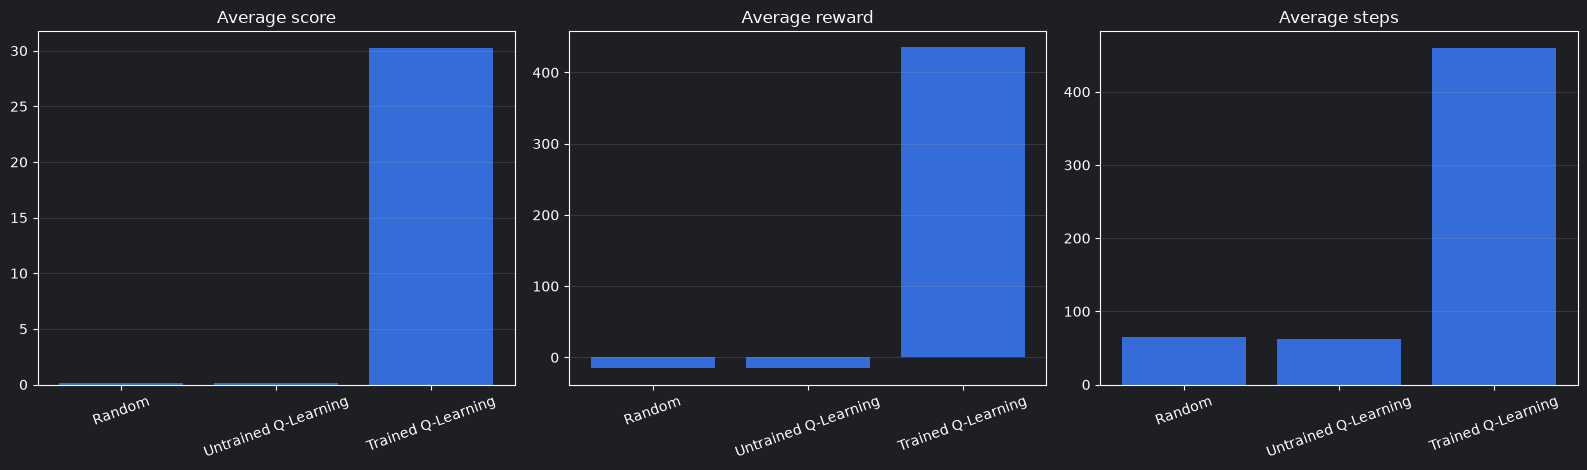

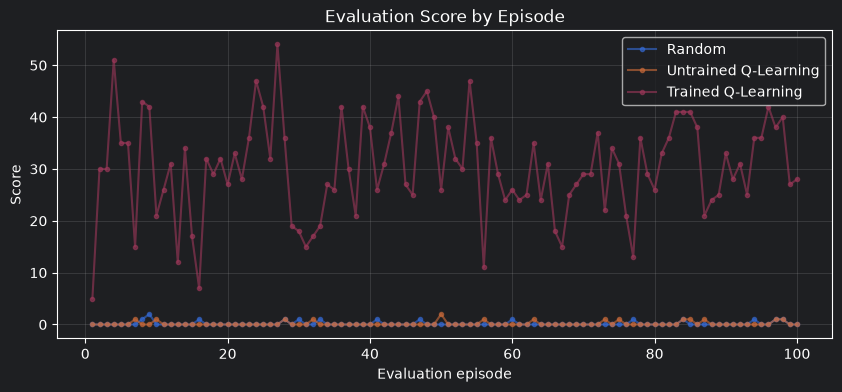

In [14]:
# Comparison charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
metrics = ["Average score", "Average reward", "Average steps"]
for ax, metric in zip(axes, metrics):
    ax.bar(evaluation_results["Agent"], evaluation_results[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
for name, data in [
    ("Random", random_eval),
    ("Untrained Q-Learning", untrained_eval),
    ("Trained Q-Learning", trained_eval)
]:
    plt.plot(data["episode"], data["score"], marker=".", alpha=0.6, label=name)
plt.title("Evaluation Score by Episode")
plt.xlabel("Evaluation episode"); plt.ylabel("Score")
plt.legend(); plt.grid(alpha=0.25); plt.show()

## Section 11 – Final Analysis

The following cell generates a short report using the actual training and evaluation measurements from this notebook. Interpret the results in light of the chosen state representation, reward design, and training budget.

In [15]:
def generate_final_analysis(history, results):
    lookup = results.set_index("Agent")
    random_avg = float(lookup.loc["Random", "Average score"])
    untrained_avg = float(lookup.loc["Untrained Q-Learning", "Average score"])
    trained_avg = float(lookup.loc["Trained Q-Learning", "Average score"])
    early_n = max(1, min(50, len(history)))
    early_avg = float(history["score"].head(early_n).mean())
    late_avg = float(history["score"].tail(early_n).mean())

    if trained_avg > random_avg:
        comparison = (f"The trained policy achieved a higher mean score than the random baseline "
                      f"({trained_avg:.2f} vs {random_avg:.2f}) in this evaluation.")
    elif trained_avg < random_avg:
        comparison = (f"The trained policy did not outperform the random baseline "
                      f"({trained_avg:.2f} vs {random_avg:.2f}); additional training or reward/state tuning is warranted.")
    else:
        comparison = "The trained policy and random baseline achieved the same mean score in this evaluation."

    improvement = ("The training curve improved from the first " + str(early_n) +
                   " episodes (mean " + f"{early_avg:.2f}" + ") to the final " +
                   str(early_n) + " episodes (mean " + f"{late_avg:.2f}" + ").")
    if late_avg <= early_avg:
        improvement += " The selected training run does not show a clear late-stage score improvement."

    report = f'''
### Q-Learning method
Q-Learning is a model-free, off-policy reinforcement-learning algorithm. It learns an estimate of the expected discounted return for each state/action pair. After each transition, the Q-value is updated toward the observed reward plus the discounted best estimated value in the next state. This notebook uses a tabular representation with 2,048 states and 3 actions.

### Epsilon-greedy exploration
With probability epsilon, the agent selects a random action (exploration); otherwise, it selects an action with the highest current Q-value (exploitation). Epsilon decays after every episode, allowing broad exploration early in training and increasingly greedy decisions later. During evaluation, epsilon is explicitly set to zero.

### Influence of the reward system
The positive food reward encourages eating. The collision penalty discourages unsafe actions. A small per-step penalty encourages efficient behavior, while distance-based shaping rewards progress toward food and penalizes moving away. Reward shaping can accelerate learning, but poorly balanced rewards may also produce unintended behavior.

### Did the agent improve?
{improvement}
{comparison}
Evaluation averages are based on {int(lookup.loc["Trained Q-Learning", "Food collected"] * 0 + EVALUATION_EPISODES)} episodes per agent. The untrained greedy policy provides a useful reference for the effect of learning.

### Random versus trained behavior
The random agent does not use experience and selects each of the three relative actions uniformly. The trained agent uses the learned Q-table to associate compact observations with actions. Compare the evaluation table rather than relying on a single visual demonstration, because Snake outcomes are stochastic.

### Limitations of tabular Q-Learning
The 11-bit state omits exact body geometry, distances, and many spatial relationships. Different board configurations can therefore map to the same state (state aliasing). Tabular methods also scale poorly as state detail grows, and the learned policy may be sensitive to reward values, random seeds, and training duration. The fixed action set and simple reward shaping further constrain behavior.

### Possible improvements
- Add richer features such as obstacle distances, food distance, and body-layout information.
- Train across multiple random seeds and report mean and standard deviation.
- Tune learning rate, discount factor, epsilon decay, and reward magnitudes systematically.
- Increase training episodes and compare learning curves.
- Consider Deep Q-Networks (DQN) for larger state representations, with experience replay and a target network.
'''
    return report

print(generate_final_analysis(training_history, evaluation_results))


### Q-Learning method
Q-Learning is a model-free, off-policy reinforcement-learning algorithm. It learns an estimate of the expected discounted return for each state/action pair. After each transition, the Q-value is updated toward the observed reward plus the discounted best estimated value in the next state. This notebook uses a tabular representation with 2,048 states and 3 actions.

### Epsilon-greedy exploration
With probability epsilon, the agent selects a random action (exploration); otherwise, it selects an action with the highest current Q-value (exploitation). Epsilon decays after every episode, allowing broad exploration early in training and increasingly greedy decisions later. During evaluation, epsilon is explicitly set to zero.

### Influence of the reward system
The positive food reward encourages eating. The collision penalty discourages unsafe actions. A small per-step penalty encourages efficient behavior, while distance-based shaping rewards progress toward food an